# Daitheon Internship — Task 1: Superstore Sales EDA

**Objective:** Analyze customer purchase volume, monthly seasonality, category-wise revenue, regional and segment performance, and discount sensitivity. This notebook cleans the supplied dataset, creates visualizations, and summarizes business findings.

**Dataset:** `data/superstore_sales.csv`

**Tools:** Python, Pandas, Matplotlib, Seaborn

## 1. Setup and imports

If a package is missing, run `pip install -r requirements.txt` in the project terminal.

In [3]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

DATA_PATH = Path("data") / "superstore_sales.csv"
if not DATA_PATH.exists():
    # Also supports running the notebook from a directory where the CSV is beside it.
    DATA_PATH = Path("superstore_sales.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Place superstore_sales.csv inside the data/ folder "
        "or beside this notebook."
    )

raw_df = pd.read_csv(DATA_PATH)
print(f"Raw dataset shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())

Raw dataset shape: 10,800 rows × 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


## 2. Initial data quality check

The provided CSV contains extra rows without essential sales/date fields. We will quantify missing values, remove records that cannot be used for sales analysis, parse dates, and retain rows with valid core fields. Missing postal codes are not required for this analysis and are left missing rather than invented.

In [4]:
quality_report = pd.DataFrame({
    "Missing_Count": raw_df.isna().sum(),
    "Missing_Percent": (raw_df.isna().mean() * 100).round(2),
    "Data_Type": raw_df.dtypes.astype(str)
}).sort_values("Missing_Count", ascending=False)

display(quality_report)
print("Duplicate rows:", int(raw_df.duplicated().sum()))

,Missing_Count,Missing_Percent,Data_Type
Postal Code,817,7.56,float64
Ship Mode,806,7.46,str
Ship Date,806,7.46,str
Customer ID,806,7.46,str
Order Date,806,7.46,str
Product ID,806,7.46,str
Category,806,7.46,str
Segment,806,7.46,str
Customer Name,806,7.46,str
Country,806,7.46,str


Duplicate rows: 504


## 3. Clean the data and engineer date features

Rows missing `Order Date`, `Sales`, `Profit`, `Category`, `Region`, or `Segment` cannot support the requested analysis, so they are removed. Dates are parsed with invalid values coerced to missing, then invalid order dates are removed. A Year-Month field is created for monthly trends.

In [5]:
df = raw_df.copy()

essential_columns = ["Order Date", "Sales", "Profit", "Category", "Region", "Segment"]
df = df.dropna(subset=essential_columns).copy()

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")
df = df.dropna(subset=["Order Date"]).copy()

for col in ["Sales", "Profit", "Quantity", "Discount"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Sales", "Profit", "Quantity", "Discount"]).copy()
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)

# Optional data validation flags; we report rather than silently alter values.
print(f"Rows before cleaning: {len(raw_df):,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Rows removed:         {len(raw_df) - len(df):,}")
print(f"Order date range:     {df['Order Date'].min().date()} to {df['Order Date'].max().date()}")
print(f"Remaining missing values: {int(df.isna().sum().sum()):,}")
display(df.head())

Rows before cleaning: 10,800
Rows after cleaning:  9,994
Rows removed:         806
Order date range:     2015-01-03 to 2018-12-30
Remaining missing values: 11


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Year-Month
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91,2017,11,2017-11
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58,2017,11,2017-11
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87,2017,6,2017-06
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03,2016,10,2016-10
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52,2016,10,2016-10


## 4. Overall sales and profit summary

In [6]:
overall_summary = pd.DataFrame({
    "Metric": ["Number of sales records", "Unique orders", "Unique customers",
               "Total sales", "Total profit", "Total quantity", "Overall profit margin"],
    "Value": [
        len(df),
        df["Order ID"].nunique(),
        df["Customer ID"].nunique(),
        df["Sales"].sum(),
        df["Profit"].sum(),
        df["Quantity"].sum(),
        (df["Profit"].sum() / df["Sales"].sum() * 100) if df["Sales"].sum() else np.nan
    ]
})
display(overall_summary)

,Metric,Value
0,Number of sales records,"9,994.00"
1,Unique orders,"5,009.00"
2,Unique customers,793.00
3,Total sales,"2,297,200.86"
4,Total profit,"286,397.02"
5,Total quantity,"37,873.00"
6,Overall profit margin,12.47


## 5. Category-wise revenue and profit

,Category,Records,Sales,Profit,Quantity,Average_Discount
2,Technology,1847,"836,154.03","145,454.95","6,939.00",0.13
0,Furniture,2121,"741,999.80","18,451.27","8,028.00",0.17
1,Office Supplies,6026,"719,047.03","122,490.80","22,906.00",0.16


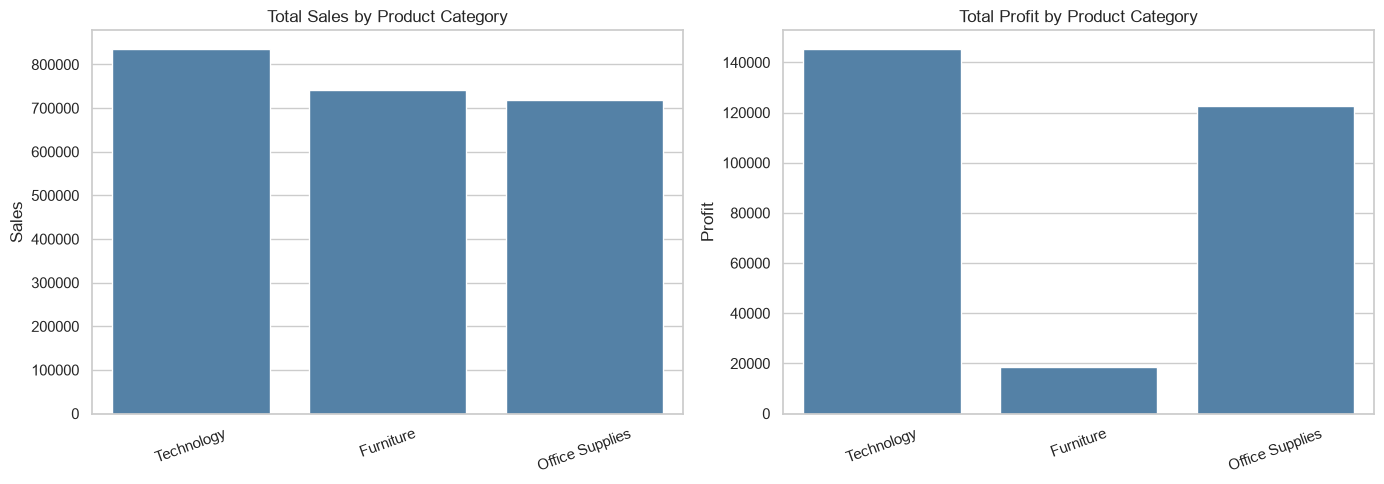

In [7]:
category_summary = (
    df.groupby("Category", as_index=False)
      .agg(Records=("Order ID", "size"),
           Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Quantity=("Quantity", "sum"),
           Average_Discount=("Discount", "mean"))
      .sort_values("Sales", ascending=False)
)
display(category_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=category_summary, x="Category", y="Sales", ax=axes[0], color="steelblue")
axes[0].set_title("Total Sales by Product Category")
axes[0].set_xlabel("")
axes[0].set_ylabel("Sales")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=category_summary, x="Category", y="Profit", ax=axes[1], color="steelblue")
axes[1].set_title("Total Profit by Product Category")
axes[1].set_xlabel("")
axes[1].set_ylabel("Profit")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 6. Monthly sales velocity and seasonality

Monthly sales are summed by order month. The line chart shows the monthly trend across the available years; peaks should be interpreted as observed patterns in this dataset, not as proof of the cause.

,Year-Month,Sales,Profit,Quantity
0,2015-01,"14,236.90","2,450.19",284.00
1,2015-02,"4,519.89",862.31,159.00
2,2015-03,"55,691.01",498.73,585.00
3,2015-04,"28,295.35","3,488.84",536.00
4,2015-05,"23,648.29","2,738.71",466.00


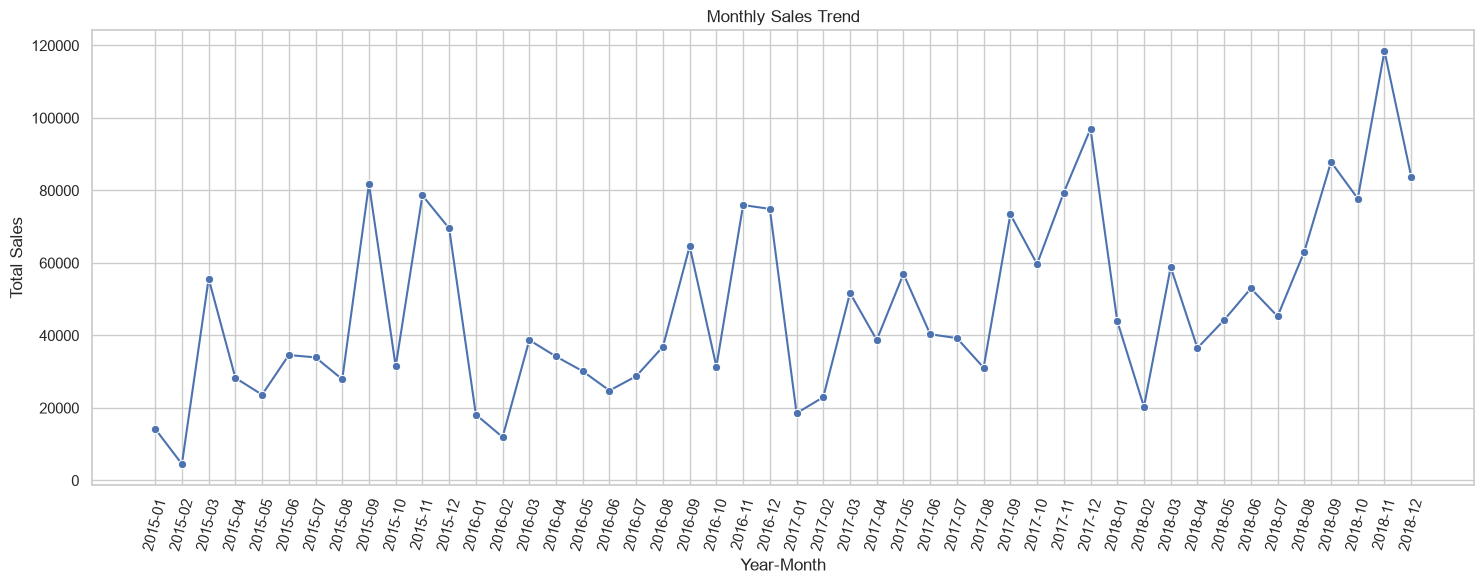

,Month_Number,Average_Monthly_Sales,Average_Monthly_Profit
0,1,"23,731.21","2,283.61"
1,2,"14,937.81","2,573.65"
2,3,"51,251.37","7,148.67"
3,4,"34,440.53","2,896.86"
4,5,"38,757.20","5,602.83"
5,6,"38,179.67","5,321.45"
6,7,"36,809.52","3,458.17"
7,8,"39,761.02","5,444.23"
8,9,"76,912.49","9,214.37"
9,10,"50,080.75","7,946.01"


In [8]:
monthly_summary = (
    df.groupby("Year-Month", as_index=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Quantity=("Quantity", "sum"))
      .sort_values("Year-Month")
)
display(monthly_summary.head())

plt.figure(figsize=(15, 6))
sns.lineplot(data=monthly_summary, x="Year-Month", y="Sales", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

monthly_summary["Month_Number"] = pd.to_datetime(monthly_summary["Year-Month"]).dt.month
seasonality = monthly_summary.groupby("Month_Number", as_index=False).agg(
    Average_Monthly_Sales=("Sales", "mean"),
    Average_Monthly_Profit=("Profit", "mean")
)
display(seasonality)

## 7. Region-wise and customer-segment performance

These summaries compare sales and profit by region and by customer segment.

,Region,Sales,Profit
3,West,"725,457.82","108,418.45"
1,East,"678,781.24","91,522.78"
0,Central,"501,239.89","39,706.36"
2,South,"391,721.91","46,749.43"


,Segment,Sales,Profit,Unique_Customers
0,Consumer,"1,161,401.34","134,119.21",409
1,Corporate,"706,146.37","91,979.13",236
2,Home Office,"429,653.15","60,298.68",148


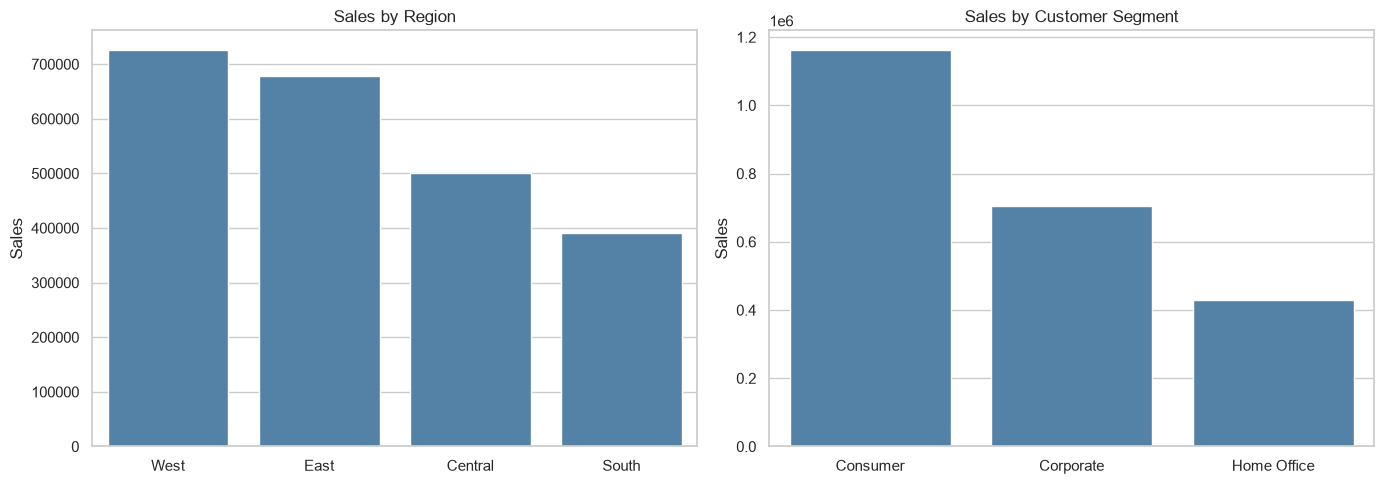

In [9]:
region_summary = (
    df.groupby("Region", as_index=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
      .sort_values("Sales", ascending=False)
)
segment_summary = (
    df.groupby("Segment", as_index=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
           Unique_Customers=("Customer ID", "nunique"))
      .sort_values("Sales", ascending=False)
)
display(region_summary)
display(segment_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=region_summary, x="Region", y="Sales", ax=axes[0], color="steelblue")
axes[0].set_title("Sales by Region")
axes[0].set_xlabel("")
sns.barplot(data=segment_summary, x="Segment", y="Sales", ax=axes[1], color="steelblue")
axes[1].set_title("Sales by Customer Segment")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

## 8. Discount sensitivity: discount versus profit

The scatter plot shows each transaction line's discount and profit. The red line is a descriptive trend line. Association does not prove that discount alone caused a profit outcome; product mix, quantity, and other factors may also matter.

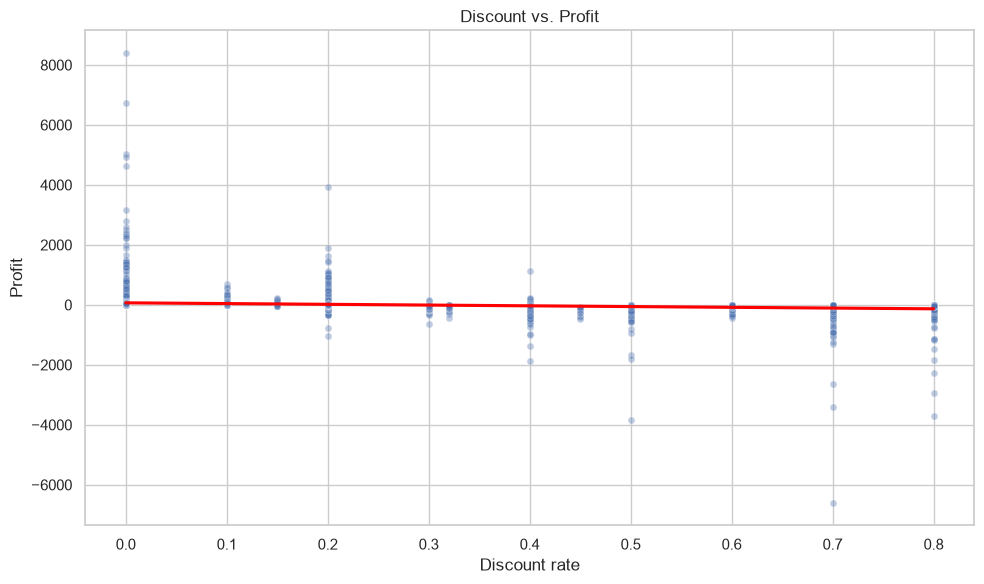

,Discount,Records,Sales,Total_Profit,Average_Profit
0,0.00,4798,"1,087,908.47","320,987.60",66.90
1,0.10,94,"54,369.35","9,029.18",96.06
2,0.15,52,"27,558.52","1,418.99",27.29
3,0.20,3657,"764,594.37","90,337.31",24.70
4,0.30,227,"103,226.65","-10,369.28",-45.68
5,0.32,27,"14,493.46","-2,391.14",-88.56
6,0.40,206,"116,417.78","-23,057.05",-111.93
7,0.45,11,"5,484.97","-2,493.11",-226.65
8,0.50,66,"58,918.54","-20,506.43",-310.70
9,0.60,138,"6,644.70","-5,944.66",-43.08


In [10]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.35, s=25)
sns.regplot(data=df, x="Discount", y="Profit", scatter=False, color="red", ci=None)
plt.title("Discount vs. Profit")
plt.xlabel("Discount rate")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

discount_summary = (
    df.groupby("Discount", as_index=False)
      .agg(Records=("Profit", "size"),
           Sales=("Sales", "sum"),
           Total_Profit=("Profit", "sum"),
           Average_Profit=("Profit", "mean"))
      .sort_values("Discount")
)
display(discount_summary)

## 9. Executive takeaways (data-driven)

The following findings are generated from the cleaned data so they stay aligned with the dataset used in the notebook. Currency values use the dataset's original units.

In [11]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
top_category = category_summary.iloc[0]
top_profit_category = category_summary.loc[category_summary["Profit"].idxmax()]
lowest_profit_category = category_summary.loc[category_summary["Profit"].idxmin()]
top_region = region_summary.iloc[0]
top_segment = segment_summary.iloc[0]
peak_month = monthly_summary.loc[monthly_summary["Sales"].idxmax()]
discount_means = discount_summary.set_index("Discount")["Average_Profit"]
zero_discount_profit = discount_means.get(0.0, np.nan)
high_discount = discount_summary[discount_summary["Discount"] >= 0.30]
high_discount_avg_profit = (
    df.loc[df["Discount"] >= 0.30, "Profit"].mean()
    if (df["Discount"] >= 0.30).any() else np.nan
)
no_discount_avg_profit = df.loc[df["Discount"] == 0, "Profit"].mean()

takeaways = [
    f"**1. Revenue and profitability baseline:** The cleaned dataset contains {len(df):,} sales records, generating {total_sales:,.2f} in sales and {total_profit:,.2f} in profit.",
    f"**2. Category revenue leader:** {top_category['Category']} has the highest total sales ({top_category['Sales']:,.2f}).",
    f"**3. Profit differs from revenue leadership:** {top_profit_category['Category']} produces the highest total profit ({top_profit_category['Profit']:,.2f}); {lowest_profit_category['Category']} has the lowest total profit ({lowest_profit_category['Profit']:,.2f}). Review margin and product mix, not just sales volume.",
    f"**4. Regional performance:** {top_region['Region']} is the highest-sales region ({top_region['Sales']:,.2f}); compare its profit with other regions before reallocating budget.",
    f"**5. Customer segment:** {top_segment['Segment']} contributes the most sales ({top_segment['Sales']:,.2f}), making it an important segment for retention and cross-sell analysis.",
    f"**6. Monthly peak:** {peak_month['Year-Month']} is the strongest month by sales ({peak_month['Sales']:,.2f}). Use monthly trends to plan inventory and promotions, and validate the pattern over additional periods.",
    f"**7. Discount sensitivity:** Average profit for records with discounts of 30% or more is {high_discount_avg_profit:,.2f}, compared with {no_discount_avg_profit:,.2f} for records with no discount. This is an association, not proof of causation; check category and product mix before changing discount policy."
]
for item in takeaways:
    display(Markdown("- " + item))

- **1. Revenue and profitability baseline:** The cleaned dataset contains 9,994 sales records, generating 2,297,200.86 in sales and 286,397.02 in profit.

- **2. Category revenue leader:** Technology has the highest total sales (836,154.03).

- **3. Profit differs from revenue leadership:** Technology produces the highest total profit (145,454.95); Furniture has the lowest total profit (18,451.27). Review margin and product mix, not just sales volume.

- **4. Regional performance:** West is the highest-sales region (725,457.82); compare its profit with other regions before reallocating budget.

- **5. Customer segment:** Consumer contributes the most sales (1,161,401.34), making it an important segment for retention and cross-sell analysis.

- **6. Monthly peak:** 2018-11 is the strongest month by sales (118,447.82). Use monthly trends to plan inventory and promotions, and validate the pattern over additional periods.

- **7. Discount sensitivity:** Average profit for records with discounts of 30% or more is -97.18, compared with 66.90 for records with no discount. This is an association, not proof of causation; check category and product mix before changing discount policy.

## 10. Data limitations and recommendations

- The source CSV includes rows without core order/sales fields; these are excluded from analysis and the removal count is printed above.
- Postal codes are not needed for this task, so missing postal codes are not imputed.
- Discount and profit relationships are observational. Test discount changes with product/category controls or a controlled experiment before making policy decisions.
- The dataset's currency unit is not explicitly established by this file, so figures are reported in the dataset's original units.

## 11. Export cleaned data and summary tables

This cell saves outputs into an `outputs/` directory so they can be reviewed or attached to the Git repository if desired.

In [12]:

from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df.to_csv(OUTPUT_DIR / "superstore_sales_cleaned.csv", index=False)
category_summary.to_csv(OUTPUT_DIR / "category_summary.csv", index=False)
region_summary.to_csv(OUTPUT_DIR / "region_summary.csv", index=False)
segment_summary.to_csv(OUTPUT_DIR / "segment_summary.csv", index=False)
monthly_summary.to_csv(OUTPUT_DIR / "monthly_sales_summary.csv", index=False)
discount_summary.to_csv(OUTPUT_DIR / "discount_profit_summary.csv", index=False)

print("Cleaned data and summary tables saved successfully.")


Cleaned data and summary tables saved successfully.
